
- **NDVI:** Normalized Difference Vegetation Index, describes the vigour level of the crop. `NDVI := (NIR-RED)/(NIR+RED)`
- **NDMI:** Normalized Difference Moisture Index, describes the crop’s water stress level. `NDMI := NIR-SWIR)/(NIR+SWIR)`

In [50]:
import ee
import geemap
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# ee.Authenticate()  # Run once
ee.Initialize(project="eo-toolkit-513110")

# Time series analysis

In [3]:
LON = 7.85  # Foret de Haguenau
LAT = 48.83  # Foret de Haguenau
RADIUS_M = 300  # We average the forest pixels inside this circle
START = "2019-01-01"
END = "2025-10-01"

In [26]:
def build_collections(lon, lat, radius_m):
    point = ee.Geometry.Point([lon, lat])
    roi = point.buffer(radius_m)
    
    # ESA WorldCover class 10 = tree cover
    forest = ee.Image("ESA/WorldCover/v200/2021").select("Map").eq(10)
    
    # Sentinel-2 Harmonized with Cloud Score+
    s2 = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
          .filterBounds(roi)
          .filterDate(START, END)
          .linkCollection(ee.ImageCollection("GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED"), ["cs_cdf"]))
    
    def indices(img):
        clear = img.select("cs_cdf").gte(0.6)
        ndvi = img.normalizedDifference(["B8", "B4"]).rename("NDVI")
        ndmi = img.normalizedDifference(["B8", "B11"]).rename("NDMI")
        return ndvi.addBands(ndmi).updateMask(clear).updateMask(forest).copyProperties(img, ["system:time_start"])
    
    def per_image(img):
        d = img.reduceRegion(ee.Reducer.mean(), roi, 10)
        return ee.Feature(None, d).set("date", img.date().format("YYYY-MM-dd"))
    
    s2_stats = ee.FeatureCollection(s2.map(indices).map(per_image)).filter(ee.Filter.notNull(["NDMI"]))
    
    # ERA5-Land Climate Data
    era = (ee.ImageCollection("ECMWF/ERA5_LAND/DAILY_AGGR")
           .filterDate(START, END)
           .select(["temperature_2m", "total_precipitation_sum"]))
    
    def era_feature(img):
        d = img.reduceRegion(ee.Reducer.mean(), point, 11132)
        return ee.Feature(None, d).set("date", img.date().format("YYYY-MM-dd"))
    
    return roi, forest, s2_stats, ee.FeatureCollection(era.map(era_feature))

In [27]:
def to_df(fc):
    rows = [f["properties"] for f in fc.getInfo()["features"]]
    df = pd.DataFrame(rows)
    df["date"] = pd.to_datetime(df["date"])
    return df.set_index("date").sort_index()

In [28]:
roi, forest, s2_stats, era_fc = build_collections(LON, LAT, RADIUS_M)

frac = forest.reduceRegion(ee.Reducer.mean(), roi, 10).getInfo()["Map"]
print(f"Forest fraction inside the circle: {frac:.0%}")

s2 = to_df(s2_stats)
s2 = s2.groupby(level=0)[["NDVI", "NDMI"]].mean() # Merge overlapping tiles of the same day
print(f"{len(s2)} clear Sentinel-2 dates")

era = to_df(era_fc)
era["temp_c"] = era["temperature_2m"] - 273.15
era["precip_mm"] = era["total_precipitation_sum"] * 1000.0

Forest fraction inside the circle: 100%
227 clear Sentinel-2 dates


In [30]:
# Weekly series and anomalies
weekly = pd.DataFrame({
    "NDVI": s2["NDVI"].resample("W").mean(),
    "NDMI": s2["NDMI"].resample("W").mean(),
    "precip": era["precip_mm"].resample("W").sum(),
    "temp": era["temp_c"].resample("W").mean(),
})

#### Compute seasonal anomalies and cumulative metrics to isolate true environmental stress from normal seasonal variations

In [31]:
# Extract the Week of Year (woy), to group the n-th week of 2019 with the same week in 2020, 2021, etc.
woy = weekly.index.isocalendar().week.values

for col in ("NDVI", "NDMI", "temp"):
    clim = weekly[col].groupby(woy).transform("median")  # Historical baseline: compute the multi-year median, for each week
    weekly[f"{col}_anom"] = weekly[col] - clim  # Subtract the historical baseline from the observed value

# Adapt to a slower response time for precipitation by taking a 30d sliding window
# (Contrarily to temperature and vegetation indices, which react relatively quickly)
weekly["precip_30d"] = weekly["precip"].rolling(4).sum()      # ~30-day rain total

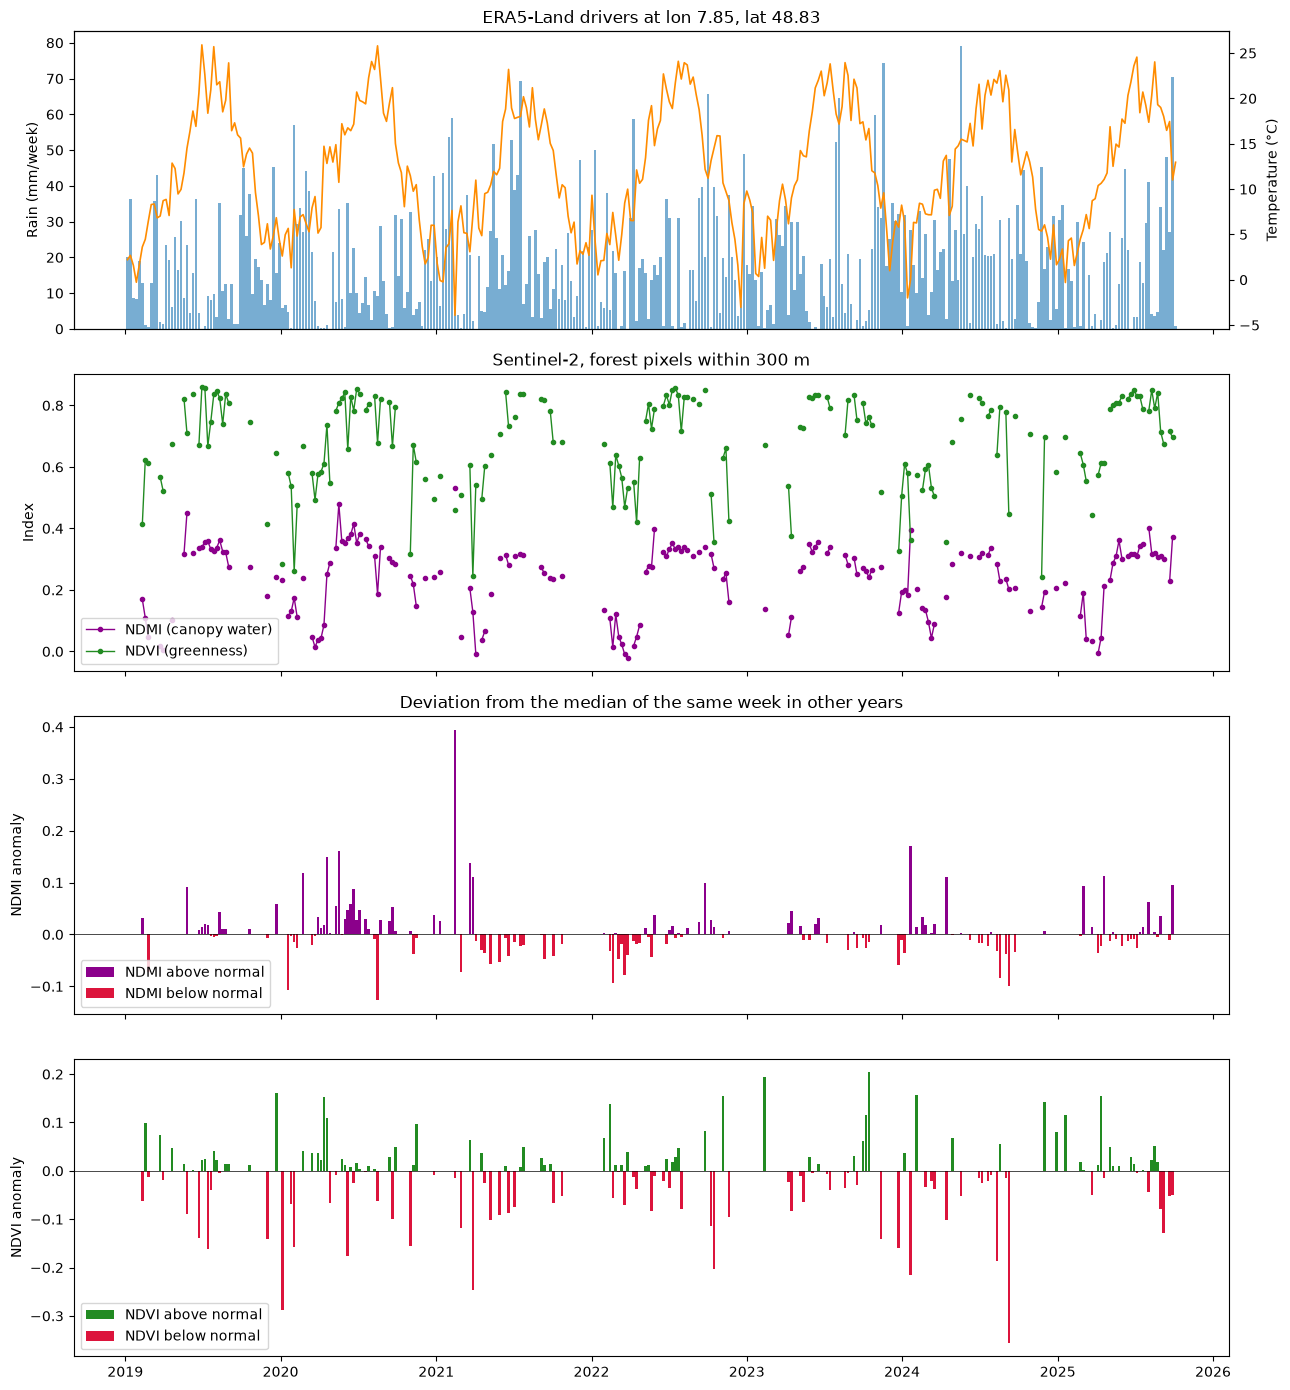

In [32]:
fig, ax = plt.subplots(4, 1, figsize=(13, 14), sharex=True)

# Climate drivers
ax[0].bar(weekly.index, weekly["precip"], width=6, color="tab:blue", alpha=0.6, label="Rain (mm/week)")
ax[0].set_ylabel("Rain (mm/week)")
t = ax[0].twinx()
t.plot(weekly.index, weekly["temp"], color="darkorange", lw=1.2, label="Temperature")
t.set_ylabel("Temperature (°C)")
ax[0].set_title(f"ERA5-Land drivers at lon {LON}, lat {LAT}")

# Raw indices
ax[1].plot(weekly.index, weekly["NDMI"], "o-", ms=3, lw=1, color="darkmagenta", label="NDMI (canopy water)")
ax[1].plot(weekly.index, weekly["NDVI"], "o-", ms=3, lw=1, color="forestgreen", label="NDVI (greenness)")
ax[1].legend(loc="lower left")
ax[1].set_ylabel("Index")
ax[1].set_title(f"Sentinel-2, forest pixels within {RADIUS_M} m")

# NDMI anomaly
a_ndmi = weekly["NDMI_anom"]
ax[2].bar(weekly.index, a_ndmi.clip(lower=0), width=6, color="darkmagenta", label="NDMI above normal")
ax[2].bar(weekly.index, a_ndmi.clip(upper=0), width=6, color="crimson", label="NDMI below normal")
ax[2].axhline(0, color="k", lw=0.5)
ax[2].legend(loc="lower left")
ax[2].set_ylabel("NDMI anomaly")
ax[2].set_title("Deviation from the median of the same week in other years")

# NDVI anomaly
a_ndvi = weekly["NDVI_anom"]
ax[3].bar(weekly.index, a_ndvi.clip(lower=0), width=6, color="forestgreen", label="NDVI above normal")
ax[3].bar(weekly.index, a_ndvi.clip(upper=0), width=6, color="crimson", label="NDVI below normal")
ax[3].axhline(0, color="k", lw=0.5)
ax[3].legend(loc="lower left")
ax[3].set_ylabel("NDVI anomaly")

plt.tight_layout()
plt.show()

#### Correlation, across multiple lags (0 to 12 weeks) for both NDMI and NDVI

In [40]:
max_lag = 12
lags = range(0, max_lag + 1)

corr_ndmi_rain = []
corr_ndmi_temp = []

corr_ndvi_rain = []
corr_ndvi_temp = []

d = weekly[["NDMI_anom", "NDVI_anom", "precip_30d", "temp_anom"]].dropna()

for lag in lags:
    # NDMI correlations
    corr_ndmi_rain.append(d["NDMI_anom"].corr(d["precip_30d"].shift(lag)))
    corr_ndmi_temp.append(d["NDMI_anom"].corr(d["temp_anom"].shift(lag)))
    
    # NDVI correlations
    corr_ndvi_rain.append(d["NDVI_anom"].corr(d["precip_30d"].shift(lag)))
    corr_ndvi_temp.append(d["NDVI_anom"].corr(d["temp_anom"].shift(lag)))

**How to interpret this chart:**

> A high Pearson coefficient at a lag of $N$ weeks indicates that canopy anomalies (NDMI or NDVI) are strongly linked to weather conditions that occurred $N$ weeks in the past, revealing the biological delay and ecological memory with which the forest responds to precipitation or heat stress.

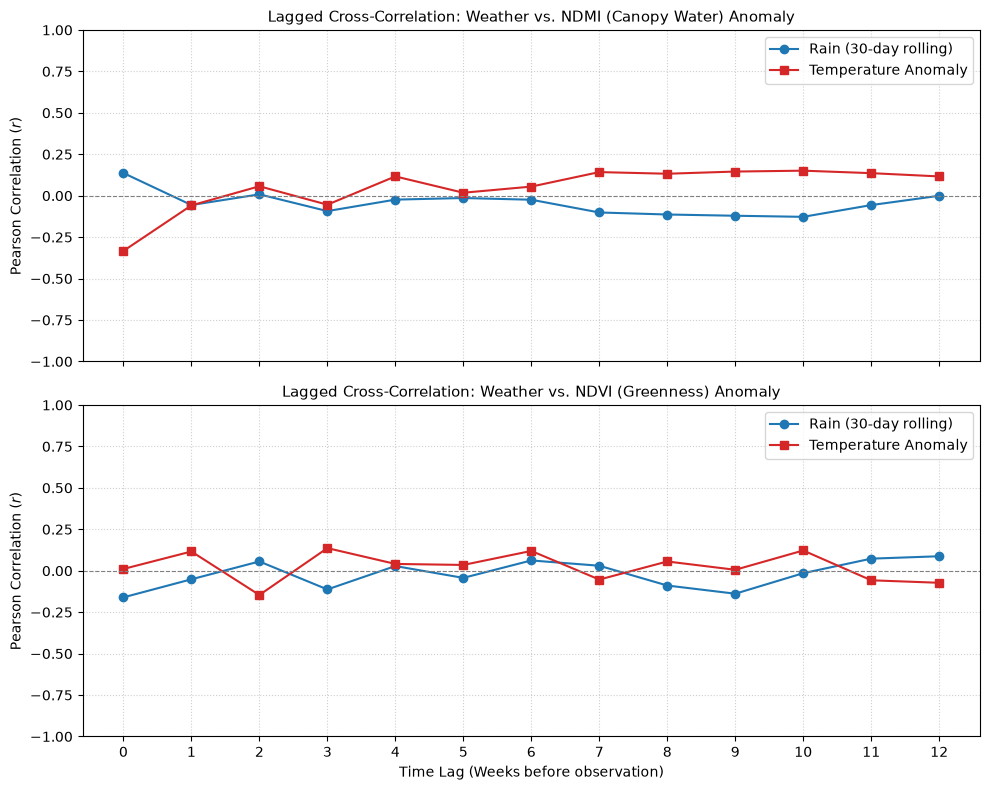

In [45]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# NDMI Lagged Correlation
axes[0].plot(lags, corr_ndmi_rain, marker='o', color='tab:blue', lw=1.5, label='Rain (30-day rolling)')
axes[0].plot(lags, corr_ndmi_temp, marker='s', color='tab:red', lw=1.5, label='Temperature Anomaly')
axes[0].axhline(0, color='grey', ls='--', lw=0.8)
axes[0].set_title("Lagged Cross-Correlation: Weather vs. NDMI (Canopy Water) Anomaly", fontsize=11)
axes[0].set_ylabel("Pearson Correlation ($r$)", fontsize=10)
axes[0].grid(True, ls=':', alpha=0.6)
axes[0].legend(loc='best')
axes[0].set_ylim(-1, 1)

# NDVI Lagged Correlation
axes[1].plot(lags, corr_ndvi_rain, marker='o', color='tab:blue', lw=1.5, label='Rain (30-day rolling)')
axes[1].plot(lags, corr_ndvi_temp, marker='s', color='tab:red', lw=1.5, label='Temperature Anomaly')
axes[1].axhline(0, color='grey', ls='--', lw=0.8)
axes[1].set_title("Lagged Cross-Correlation: Weather vs. NDVI (Greenness) Anomaly", fontsize=11)
axes[1].set_xlabel("Time Lag (Weeks before observation)", fontsize=10)
axes[1].set_ylabel("Pearson Correlation ($r$)", fontsize=10)
axes[1].set_xticks(lags)
axes[1].grid(True, ls=':', alpha=0.6)
axes[1].legend(loc='best')
axes[1].set_ylim(-1, 1)

plt.tight_layout()
plt.show()

# Pixel-wise summer NDMI anomaly

In [ ]:
# Helper function to process and mask an S2 image
def get_s2_ndmi(img):
    clear = img.select("cs_cdf").gte(0.6)
    ndmi = img.normalizedDifference(["B8", "B11"]).rename("NDMI")
    return ndmi.updateMask(clear).updateMask(forest)

In [47]:
LON = 7.85
LAT = 48.83
RADIUS_M = 5_000

point = ee.Geometry.Point([LON, LAT])
roi = point.buffer(RADIUS_M)

# Forest mask (ESA WorldCover class 10 = tree cover)
forest = ee.Image("ESA/WorldCover/v200/2021").select("Map").eq(10)

# Base Sentinel-2 collection with Cloud Score+
s2_col = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
          .filterBounds(roi)
          .linkCollection(ee.ImageCollection("GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED"), ["cs_cdf"]))

# Define baseline climatology (e.g., Summer median for 2019–2023, Summer defined as June 1 to August 31)
baseline_summer = (s2_col
                   .filterDate("2019-06-01", "2023-08-31")
                   .filter(ee.Filter.calendarRange(6, 8, "month"))
                   .map(get_s2_ndmi)
                   .median())

# Define target stress summer (e.g., Summer 2022 drought)
target_summer = (s2_col
                 .filterDate("2022-06-01", "2022-08-31")
                 .filter(ee.Filter.calendarRange(6, 8, "month"))
                 .map(get_s2_ndmi)
                 .median())

# Compute anomaly: Target summer minus baseline climatology
ndmi_anomaly = target_summer.subtract(baseline_summer).updateMask(forest)

# Visualization parameters
vis_params = {
    'min': -0.25,
    'max': 0.25,
    'palette': ['darkred', 'red', 'orange', 'white', 'lightblue', 'blue', 'darkblue']
}

**How to interpret this map:**

> Negative anomaly (red): drier than normal (stressed stands)
> 
> Positive anomaly (blue): wetter than normal

In [52]:
Map = geemap.Map(center=[LAT, LON], zoom=12)
Map.addLayer(forest.updateMask(forest), {'palette': 'green'}, 'Forest Mask', False)
Map.addLayer(ndmi_anomaly, vis_params, 'NDMI Summer 2022 Anomaly')

Map.add_colorbar(vis_params, label='NDMI Anomaly (2022 vs 2019-2023 Baseline)')

display(Map)

Map(center=[48.83, 7.85], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright',…